# Customer Intelligence Engine
## 03. Exploratory Data Analysis

### Objective

This notebook explores sales performance and customer
purchasing behaviour using the cleaned Online Retail II dataset.

The analysis focuses on five business questions:

1. How much sales value did the business generate?
2. How did monthly sales change over time?
3. Which products generated the most sales?
4. What are the sales pattern of different countries excluding the UK?
5. What can we learn about customer purchasing behaviour?

The findings will help identify sales patterns and
potential opportunities for the business.

Note: Sales value represents positive transaction-line
sales before accounting for returns and cancellations.

## 1. Import libraries

Import the libraries needed for data analysis and visualisation

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load Cleaned Data

Load the cleaned sales dataset prepared in Notebook 02.

This dataset contains positive-quantity and
positive-price transactions, excluding cancelled
invoices and exact duplicate rows.

In [18]:
# Load cleaned sales data
df = pd.read_csv("/Users/richardnguyenk/Downloads/GitHub Project/customer-intelligence-engine/data/processed/sales_clean.csv")

# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Preview the dataset
df.head()

/var/folders/v_/hp7l2sts359cczgm00f3h5xh0000gn/T/ipykernel_30818/1274852563.py:2: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/Users/richardnguyenk/Downloads/GitHub Project/customer-intelligence-engine/data/processed/sales_clean.csv")


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalSales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [19]:
# Check the dataset size again

print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

Number of records: 1007913
Number of columns: 9


## 3. Overall Sales Performance

This section provides an overview of the retailer's
sales performance.

We will calculate:
- Total sales value
- Number of unique invoices
- Total units sold
- Average sales value per invoice

In [20]:
# Calculate key sales metrics
total_sales = df["TotalSales"].sum() 

total_orders = df["Invoice"].nunique()

total_units = df["Quantity"].sum()

average_order_value = total_sales / total_orders

# Display results
print("Total sales: £", round(total_sales, 2))
print("Total orders:", total_orders)
print("Total units sold:", total_units)
print("Average order value: £", round(average_order_value, 2))

Total sales: £ 20476260.45
Total orders: 40079
Total units sold: 11205148
Average order value: £ 510.9


## 4. Monthly Sales Trends

Analyse monthly sales performance to identify
trends and potential seasonal patterns.

Understanding these patterns can help businesses
plan inventory, staffing and marketing activities.

In [21]:
# Create a column for each month
df["Month"] = df["InvoiceDate"].dt.to_period("M")

In [22]:
# Calculate total sales for each month
monthly_sales = (
    df.groupby("Month")["TotalSales"]
    .sum()
    .sort_index()
)

# Display monthly sales
display(monthly_sales)

Month
2009-12     822483.950
2010-01     651155.112
2010-02     551504.726
2010-03     830915.261
2010-04     678875.252
2010-05     657705.500
2010-06     749537.310
2010-07     648810.270
2010-08     695251.910
2010-09     921696.991
2010-10    1161902.220
2010-11    1464293.142
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637808.330
Freq: M, Name: TotalSales, dtype: float64

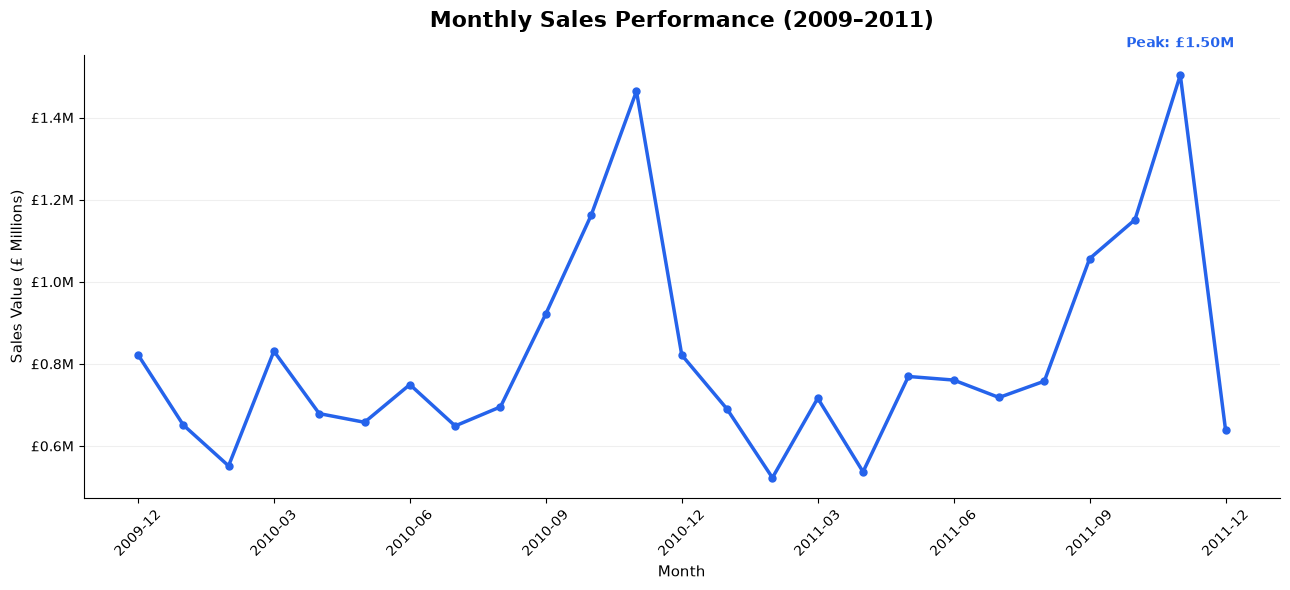

In [23]:
# Monthly Sales Performance

from matplotlib.ticker import FuncFormatter

# Create the chart
plt.figure(figsize=(13, 6))

# Plot monthly sales
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    color="#2563EB",
    linewidth=2.5,
    marker="o",
    markersize=5
)

# Format Y-axis in millions
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"£{x/1_000_000:.1f}M")
)

# Chart titles
plt.title(
    "Monthly Sales Performance (2009–2011)",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Month", fontsize=11)
plt.ylabel("Sales Value (£ Millions)", fontsize=11)

# Show every third month
plt.xticks(
    range(0, len(monthly_sales), 3),
    monthly_sales.index.astype(str)[::3],
    rotation=45
)

# Add subtle horizontal gridlines
plt.grid(axis="y", alpha=0.2)

# Remove unnecessary borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

# Find the highest sales month
highest_month = monthly_sales.idxmax()
highest_sales = monthly_sales.max()

# Highlight the highest point
plt.annotate(
    f"Peak: £{highest_sales/1_000_000:.2f}M",
    xy=(monthly_sales.index.get_loc(highest_month), highest_sales),
    xytext=(0, 20),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#2563EB"
)

plt.tight_layout()
plt.show()

### Key Findings — Monthly Sales Performance

Monthly sales fluctuated throughout the two-year period, with noticeable increases towards the end of both 2010 and 2011.

November recorded particularly strong sales in both years, suggesting a potential seasonal pattern in customer demand.

The decline observed in December 2011 should be interpreted carefully, as the dataset only includes transactions from the beginning of that month.

Further analysis is needed to determine whether these patterns are consistent across different product categories and customer groups.

## 5. Product Performance

This section identifies the top 10 products by sales value.

Understanding product performance helps the business
identify its strongest-selling products and make
better inventory and sales decisions.

In [24]:
# Calculate total sales for each product
product_sales = df.groupby(
    ["StockCode", "Description"]
)["TotalSales"].sum()

# Find the top 10 products
top_products = product_sales.sort_values(
    ascending=False
).head(10)

# Display results
top_products

StockCode  Description                       
M          Manual                                339226.24
22423      REGENCY CAKESTAND 3 TIER              330590.32
DOT        DOTCOM POSTAGE                        309854.11
85123A     WHITE HANGING HEART T-LIGHT HOLDER    257546.20
23843      PAPER CRAFT , LITTLE BIRDIE           168469.60
47566      PARTY BUNTING                         148318.28
85099B     JUMBO BAG RED RETROSPOT               145961.83
84879      ASSORTED COLOUR BIRD ORNAMENT         129324.49
POST       POSTAGE                               125682.42
22086      PAPER CHAIN KIT 50'S CHRISTMAS        117760.29
Name: TotalSales, dtype: float64

In [25]:
# Exclude known non-product codes
exclude_codes = ["M", "DOT", "POST"]

# Create a dataset containing retail products
products = df[
    ~df["StockCode"].isin(exclude_codes)
].copy()

# Calculate sales by product
product_sales = products.groupby(
    ["StockCode", "Description"]
)["TotalSales"].sum()

# Find the top 10 products
top_products = product_sales.sort_values(
    ascending=False
).head(10)

# Display results
top_products

StockCode  Description                        
22423      REGENCY CAKESTAND 3 TIER               330590.32
85123A     WHITE HANGING HEART T-LIGHT HOLDER     257546.20
23843      PAPER CRAFT , LITTLE BIRDIE            168469.60
47566      PARTY BUNTING                          148318.28
85099B     JUMBO BAG RED RETROSPOT                145961.83
84879      ASSORTED COLOUR BIRD ORNAMENT          129324.49
22086      PAPER CHAIN KIT 50'S CHRISTMAS         117760.29
23166      MEDIUM CERAMIC TOP STORAGE JAR          81700.92
79321      CHILLI LIGHTS                           80540.88
84347      ROTATING SILVER ANGELS T-LIGHT HLDR     71300.40
Name: TotalSales, dtype: float64

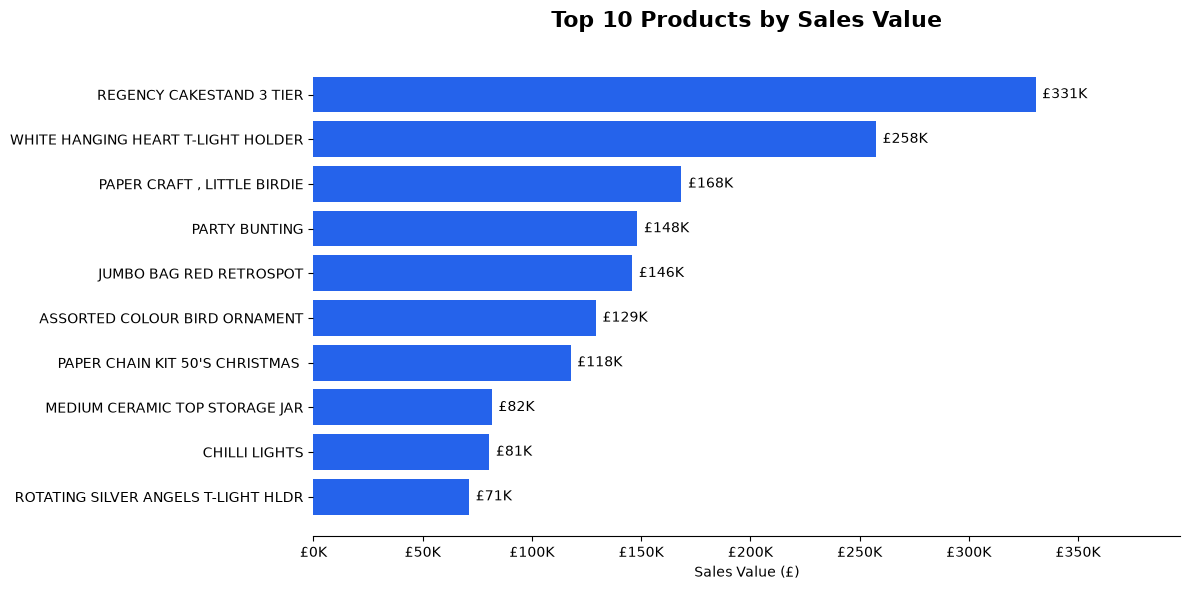

In [26]:
# Prepare product names and sales values
product_names = top_products.index.get_level_values("Description")
sales_values = top_products.values

# Create the chart
plt.figure(figsize=(12, 6))

bars = plt.barh(
    product_names[::-1],
    sales_values[::-1],
    color="#2563EB"
)

# Add sales values at the end of each bar
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 3000,
        bar.get_y() + bar.get_height() / 2,
        f"£{width / 1000:,.0f}K",
        va="center",
        fontsize=10
    )

# Chart title and labels
plt.title(
    "Top 10 Products by Sales Value",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Sales Value (£)")
plt.ylabel("")

# Format X-axis in thousands
from matplotlib.ticker import FuncFormatter

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"£{x / 1000:.0f}K")
)

# Add space for the value labels
plt.xlim(0, max(sales_values) * 1.2)

# Remove unnecessary borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

### Key Findings — Product Performance

The analysis shows that REGENCY CAKESTAND 3 TIER generated the highest sales value at approximately £331K, followed by WHITE HANGING HEART T-LIGHT HOLDER at £258K.

Both products performed considerably better than the remaining products in the Top 10, suggesting that they are important contributors to the retailer's sales.

From a business perspective, understanding which products generate the most sales can help management prioritise inventory planning and monitor demand for popular items.

However, sales value alone does not indicate profitability. Further analysis of quantities sold, product costs and returns would provide a more complete picture of product performance.

## 6. International Market Analysis

This section explores sales performance outside
the United Kingdom.

Instead of comparing total sales alone, I will
investigate order volume and average order value
to identify differences between international markets.

In [27]:
# Exclude the United Kingdom
international = df[df["Country"] != "United Kingdom"].copy()

# Calculate sales and order counts by country
country_analysis = international.groupby("Country").agg(
    TotalSales=("TotalSales", "sum"),
    TotalOrders=("Invoice", "nunique")
)

# Calculate average order value
country_analysis["AverageOrderValue"] = (
    country_analysis["TotalSales"] / country_analysis["TotalOrders"]
)

# Display the top 10 international markets
country_analysis.sort_values(
    by="TotalSales",
    ascending=False
).head(10).round(2)

,TotalSales,TotalOrders,AverageOrderValue
Country,,,
EIRE,658767.31,626,1052.34
Netherlands,554038.09,228,2429.99
Germany,425019.71,789,538.68
France,350456.09,623,562.53
Australia,169283.46,95,1781.93
Spain,108332.49,154,703.46
Switzerland,100685.59,93,1082.64
Sweden,91869.82,105,874.95
Denmark,68580.69,43,1594.90


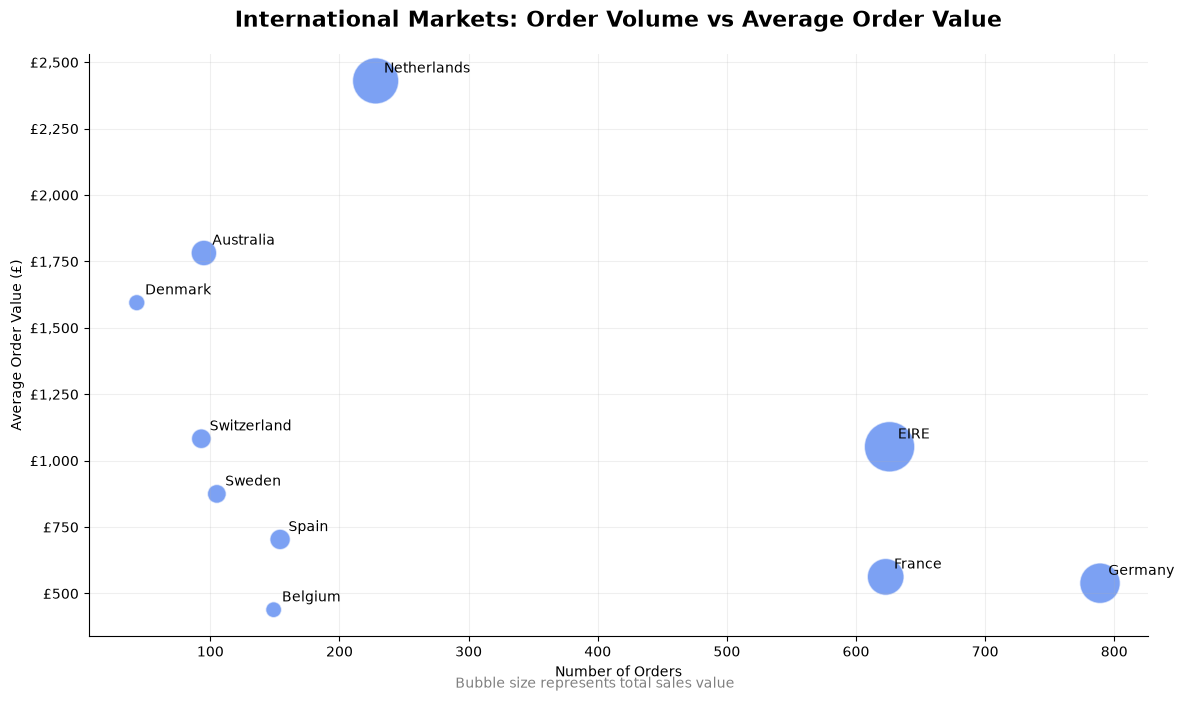

In [28]:
# Create the International Market: Order Volume vs. Average Order Value chart

# Select the top 10 international markets
top_markets = country_analysis.sort_values(
    by="TotalSales",
    ascending=False
).head(10)

# Create the chart
plt.figure(figsize=(12, 7))

plt.scatter(
    top_markets["TotalOrders"],
    top_markets["AverageOrderValue"],
    s=top_markets["TotalSales"] / 500,
    color="#2563EB",
    alpha=0.6,
    edgecolors="white"
)

# Add country labels
for country, row in top_markets.iterrows():
    plt.annotate(
        country,
        (row["TotalOrders"], row["AverageOrderValue"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=10
    )

# Chart title and labels
plt.title(
    "International Markets: Order Volume vs Average Order Value",
    fontsize=16,
    fontweight="bold",
    pad=20
)
 

plt.xlabel("Number of Orders")
plt.ylabel("Average Order Value (£)")

# Format currency axis
from matplotlib.ticker import FuncFormatter

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"£{x:,.0f}")
)

# Improve appearance
plt.grid(alpha=0.2)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.figtext(
    0.5, 0.01,
    "Bubble size represents total sales value",
    ha="center",
    fontsize=10,
    color="gray"
)

plt.tight_layout()
plt.show()

### Key Findings — International Market Analysis

The analysis reveals different purchasing patterns across the retailer's international markets.

The Netherlands recorded the highest average order value among the ten markets analysed, at approximately £2,430, despite having only 228 orders. In comparison, Germany recorded 789 orders but a much lower average order value of approximately £539.

Australia and Denmark also showed relatively high average order values but lower order volumes, suggesting that their sales may be driven by fewer, larger purchases.

These findings suggest that different international markets may require different business strategies. Markets with high order volumes could benefit from customer retention initiatives, while markets with high average order values may warrant further investigation into customer concentration and repeat purchasing.

However, additional information on shipping costs, profitability and customer behaviour would be needed before making investment or expansion decisions.

## 7. Customer Purchasing Behaviour

This section examines how sales value is distributed
across the retailer's customers.

The main objective is to understand whether sales
are concentrated among a small group of customers
or distributed more evenly.

Business Question:
How much of the retailer's customer-linked sales
comes from its highest-spending customers?

In [30]:
# Load the cleaned customer dataset
customers = pd.read_csv("/Users/richardnguyenk/Downloads/GitHub Project/customer-intelligence-engine/data/processed/customers_clean.csv")

# Calculate total spending for each customer
customer_spending = customers.groupby("Customer ID")["TotalSales"].sum()

# Sort customers from highest to lowest spending
customer_spending = customer_spending.sort_values(ascending=False)

# Display the top 10 customers
customer_spending.head(10)

Customer ID
18102    580987.04
14646    528602.52
14156    313437.62
14911    291420.81
17450    244784.25
13694    195640.69
17511    172132.87
16446    168472.50
16684    147142.77
12415    144458.37
Name: TotalSales, dtype: float64

In [31]:
# Count the number of unique customers
total_customers = customer_spending.count()

print("Total unique customers:", total_customers)

Total unique customers: 5878


In [32]:
# Calculate the number of customers in the top 10%
top_10_count = round(total_customers * 0.10)

# Calculate sales from the top 10% of customers
top_10_sales = customer_spending.head(top_10_count).sum()

# Calculate total customer-linked sales
total_customer_sales = customer_spending.sum()

# Calculate the percentage contributed by the top 10%
top_10_percentage = (top_10_sales / total_customer_sales) * 100

print("Top 10% customers:", top_10_count)
print("Sales contribution:", round(top_10_percentage, 2), "%")

Top 10% customers: 588
Sales contribution: 63.93 %


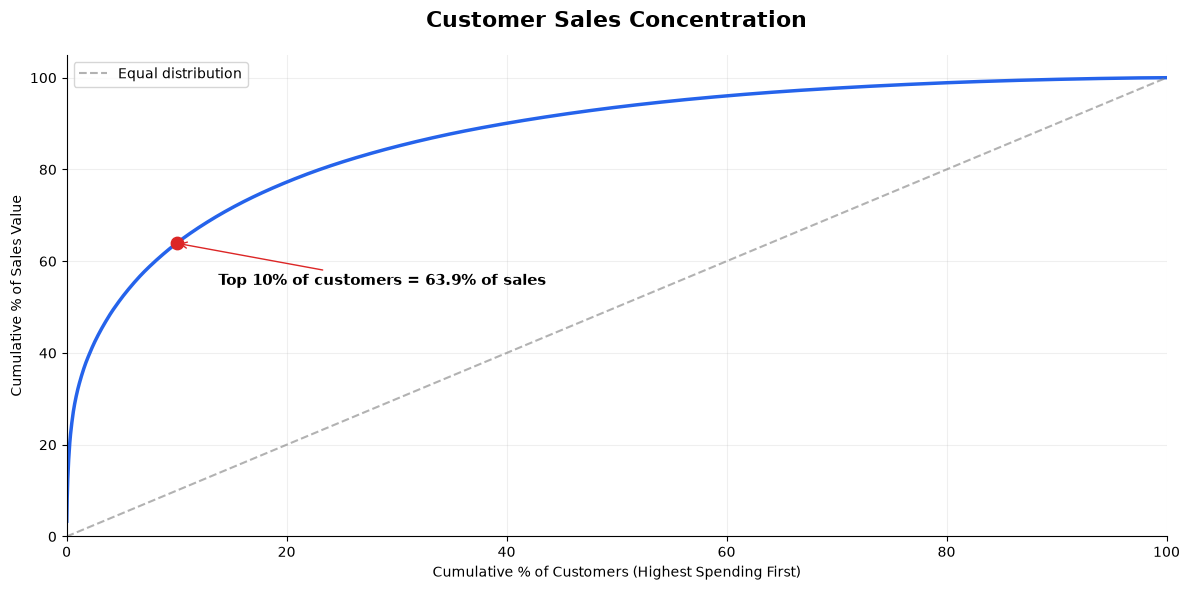

In [33]:
# Calculate cumulative sales percentage
cumulative_sales = customer_spending.cumsum() / customer_spending.sum() * 100

# Calculate cumulative customer percentage
cumulative_customers = (
    pd.Series(range(1, len(customer_spending) + 1))
    / len(customer_spending) * 100
)

# Create chart
plt.figure(figsize=(12, 6))

plt.plot(
    cumulative_customers,
    cumulative_sales.values,
    color="#2563EB",
    linewidth=2.5
)

# Highlight the top 10% of customers
plt.scatter(
    10,
    top_10_percentage,
    color="#DC2626",
    s=80,
    zorder=5
)

# Highlight the contribution of the top 10%
plt.annotate(
    f"Top 10% of customers = {top_10_percentage:.1f}% of sales",
    xy=(10, top_10_percentage),
    xytext=(30, -30),
    textcoords="offset points",
    fontsize=11,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color="#DC2626"
    )
)

# Add an equal-distribution reference line
plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="gray",
    alpha=0.6,
    label="Equal distribution"
)

# Chart labels
plt.title(
    "Customer Sales Concentration",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Cumulative % of Customers (Highest Spending First)")
plt.ylabel("Cumulative % of Sales Value")

plt.xlim(0, 100)
plt.ylim(0, 105)

plt.grid(alpha=0.2)
plt.legend()

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Key Findings — Customer Sales Concentration

The analysis identified 5,878 unique customers, with the top 10% (588 customers) contributing approximately 63.93% of customer-linked sales value.

The cumulative sales curve shows that a relatively small group of high-spending customers accounts for a large proportion of the retailer's sales.

This suggests that customer retention could be particularly important for maintaining sales performance. Losing major customers may have a significant impact on the business.

However, high spending does not necessarily mean high profitability or strong customer loyalty. Further analysis of purchase frequency, recency and customer spending patterns is needed to better understand these customers.

These findings provide a foundation for customer segmentation using RFM analysis.

## 8. Executive Summary

This analysis explored the sales performance, product demand, international markets and customer purchasing behaviour of a UK-based online retailer between December 2009 and December 2011.

### Key Findings

**Sales Trends:** Sales increased noticeably towards the end of both years, with November recording particularly strong performance. This suggests a possible seasonal increase in demand.

**Product Performance:** REGENCY CAKESTAND 3 TIER was the highest-selling product by value, generating approximately £331K, followed by WHITE HANGING HEART T-LIGHT HOLDER at £258K.

**International Markets:** Purchasing patterns varied across countries. The Netherlands had a relatively high average order value of £2,430, while Germany recorded more orders but a lower average order value of £539.

**Customer Concentration:** The top 10% of identifiable customers (588 customers) contributed 63.93% of customer-linked positive sales value, indicating substantial sales concentration.

### Business Implications

The findings highlight the importance of monitoring seasonal demand, understanding international purchasing patterns and retaining high-spending customers.

However, sales value does not account for returns, product costs or profitability. Further analysis is required before making commercial decisions.

### Next Step

The next stage will use RFM analysis to segment customers based on their purchasing behaviour and identify opportunities for customer retention and engagement.